## import 3 librarys ##

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## import the csv file from data file ##

In [2]:
df = pd.read_csv('data/heart.csv')
df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


In [3]:
df.shape
df.info()
df.describe()
df.isnull().sum()
df.duplicated().sum()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


np.int64(0)

In [4]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [5]:
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [6]:
(df['Cholesterol']==0).sum()

np.int64(172)

## catching data mistakes and clean it ##

In [7]:
df["Cholesterol"] = df["Cholesterol"].replace(0, np.nan)

In [8]:
df['Cholesterol'].isnull().sum()

np.int64(172)

In [9]:
df['Cholesterol'].median()


np.float64(237.0)

In [10]:

df['Cholesterol'].mean()


np.float64(244.6353887399464)

In [11]:
df[df['Cholesterol'].isnull()]['HeartDisease'].value_counts()

HeartDisease
1    152
0     20
Name: count, dtype: int64

In [12]:
df["Cholesterol_filled"] = df["Cholesterol"].fillna(df["Cholesterol"].median())
df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,Cholesterol_filled
0,40,M,ATA,140,289.0,0,Normal,172,N,0.0,Up,0,289.0
1,49,F,NAP,160,180.0,0,Normal,156,N,1.0,Flat,1,180.0
2,37,M,ATA,130,283.0,0,ST,98,N,0.0,Up,0,283.0
3,48,F,ASY,138,214.0,0,Normal,108,Y,1.5,Flat,1,214.0
4,54,M,NAP,150,195.0,0,Normal,122,N,0.0,Up,0,195.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264.0,0,Normal,132,N,1.2,Flat,1,264.0
914,68,M,ASY,144,193.0,1,Normal,141,N,3.4,Flat,1,193.0
915,57,M,ASY,130,131.0,0,Normal,115,Y,1.2,Flat,1,131.0
916,57,F,ATA,130,236.0,0,LVH,174,N,0.0,Flat,1,236.0


In [13]:
(df['RestingBP']==0).sum()

np.int64(1)

In [14]:
(df['RestingBP'].isnull())

0      False
1      False
2      False
3      False
4      False
       ...  
913    False
914    False
915    False
916    False
917    False
Name: RestingBP, Length: 918, dtype: bool

In [15]:
df[df["RestingBP"] == 0]

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,Cholesterol_filled
449,55,M,NAP,0,NaN,0,Normal,155,N,1.5,Flat,1,237.0


In [16]:
df = df[df["RestingBP"] != 0]
df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,Cholesterol_filled
0,40,M,ATA,140,289.0,0,Normal,172,N,0.0,Up,0,289.0
1,49,F,NAP,160,180.0,0,Normal,156,N,1.0,Flat,1,180.0
2,37,M,ATA,130,283.0,0,ST,98,N,0.0,Up,0,283.0
3,48,F,ASY,138,214.0,0,Normal,108,Y,1.5,Flat,1,214.0
4,54,M,NAP,150,195.0,0,Normal,122,N,0.0,Up,0,195.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264.0,0,Normal,132,N,1.2,Flat,1,264.0
914,68,M,ASY,144,193.0,1,Normal,141,N,3.4,Flat,1,193.0
915,57,M,ASY,130,131.0,0,Normal,115,Y,1.2,Flat,1,131.0
916,57,F,ATA,130,236.0,0,LVH,174,N,0.0,Flat,1,236.0


In [17]:
df = df.reset_index(drop=True)

In [18]:
df.shape

(917, 13)

In [19]:
df['HeartDisease'].value_counts()

HeartDisease
1    507
0    410
Name: count, dtype: int64

In [20]:
df['HeartDisease'].value_counts(normalize=True)*100

HeartDisease
1    55.288986
0    44.711014
Name: proportion, dtype: float64

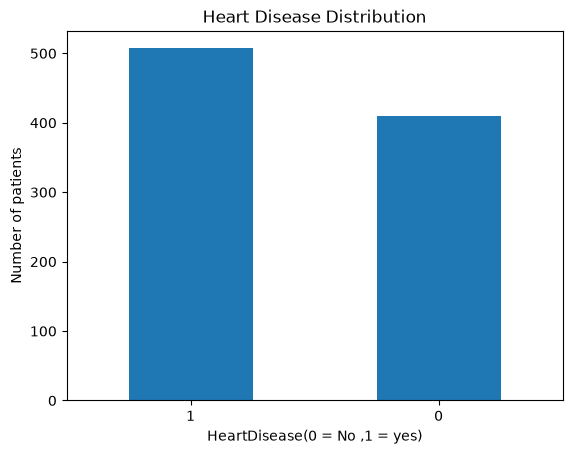

In [21]:
df['HeartDisease'].value_counts().plot(kind='bar')
plt.title('Heart Disease Distribution')
plt.xlabel('HeartDisease(0 = No ,1 = yes)')
plt.ylabel('Number of patients')
plt.xticks(rotation=0)
plt.show()

## according to sex ##

In [34]:
df['Sex'].value_counts()

Sex
M    724
F    193
Name: count, dtype: int64

In [23]:
df.groupby('Sex')['HeartDisease'].mean()*100

Sex
F    25.906736
M    63.121547
Name: HeartDisease, dtype: float64

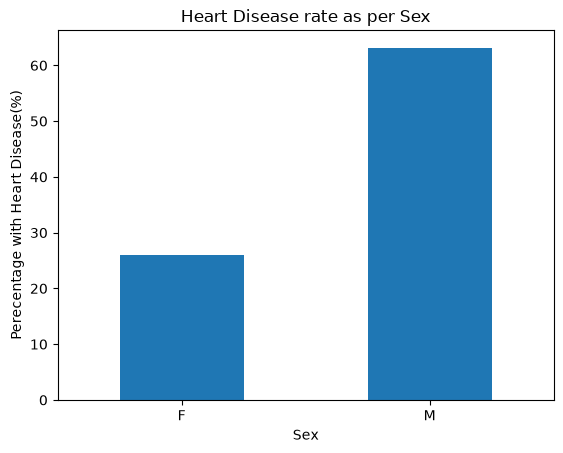

In [24]:
(df.groupby('Sex')['HeartDisease'].mean()*100).plot(kind='bar')
plt.title('Heart Disease rate as per Sex')
plt.xlabel('Sex')
plt.ylabel('Perecentage with Heart Disease(%)')
plt.xticks(rotation=0)
plt.show()

## category by age ##

In [25]:
df.groupby('HeartDisease')['Age'].mean()

HeartDisease
0    50.551220
1    55.901381
Name: Age, dtype: float64

In [26]:
df['Sex'].value_counts()


Sex
M    724
F    193
Name: count, dtype: int64

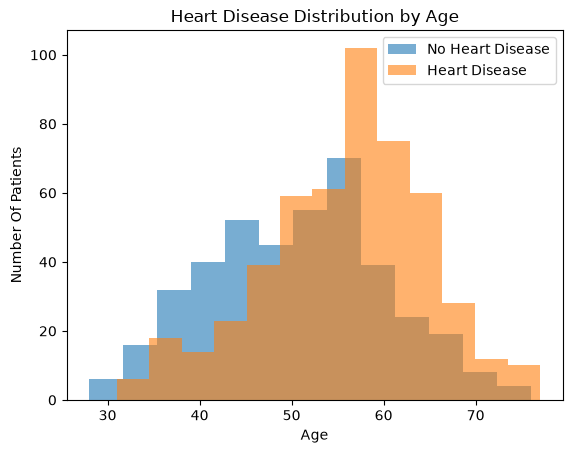

In [27]:
df[df['HeartDisease']==0]['Age'].plot(kind='hist',alpha=0.6,label="No Heart Disease",bins=13)
df[df['HeartDisease']==1]['Age'].plot(kind='hist',alpha=0.6,label="Heart Disease",bins=13)
plt.title('Heart Disease Distribution by Age')
plt.xlabel('Age')
plt.ylabel('Number Of Patients')
plt.legend()
plt.show()

## chest pain type ##

In [28]:
df['ChestPainType'].value_counts()

ChestPainType
ASY    496
NAP    202
ATA    173
TA      46
Name: count, dtype: int64

In [29]:
(df.groupby('ChestPainType')['HeartDisease'].mean()*100).sort_values()

ChestPainType
ATA    13.872832
NAP    35.148515
TA     43.478261
ASY    79.032258
Name: HeartDisease, dtype: float64

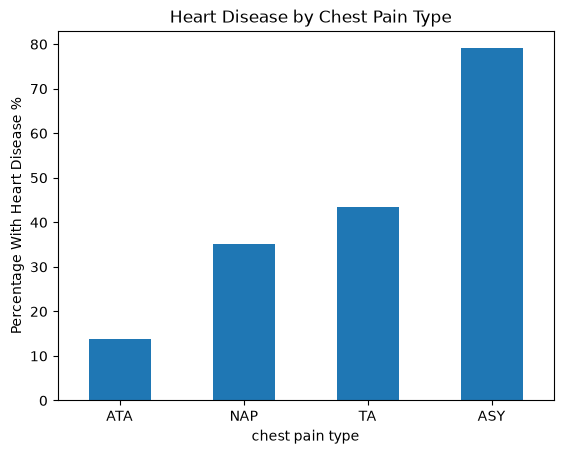

In [30]:
(df.groupby('ChestPainType')['HeartDisease'].mean()*100).sort_values().plot(kind="bar")
plt.title('  Heart Disease by Chest Pain Type')
plt.xlabel('chest pain type')
plt.ylabel('Percentage With Heart Disease %')
plt.xticks(rotation=0)
plt.show()

## Boxplot ##

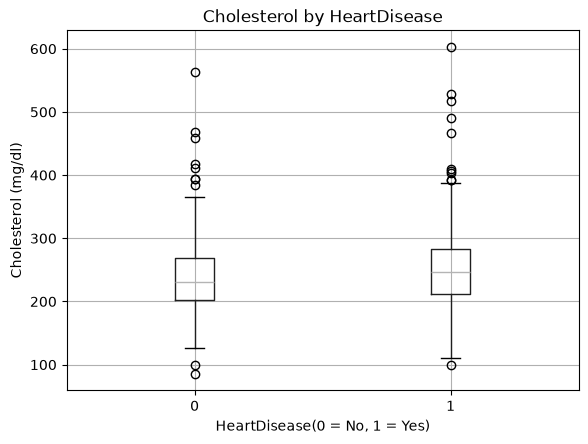

In [31]:
df.boxplot(column='Cholesterol',by='HeartDisease')
plt.suptitle('')
plt.title('Cholesterol by HeartDisease')
plt.xlabel('HeartDisease(0 = No, 1 = Yes)')
plt.ylabel('Cholesterol (mg/dl)')
plt.show()

## my last project show ##

In [32]:
num_cols = ["Age","RestingBP","Cholesterol","MaxHR","HeartDisease"]
df[num_cols].corr()

,Age,RestingBP,Cholesterol,MaxHR,HeartDisease
Age,1.000000,0.263084,0.058758,-0.382280,0.282012
RestingBP,0.263084,1.000000,0.095939,-0.109693,0.117990
Cholesterol,0.058758,0.095939,1.000000,-0.019856,0.103866
MaxHR,-0.382280,-0.109693,-0.019856,1.000000,-0.401410
HeartDisease,0.282012,0.117990,0.103866,-0.401410,1.000000


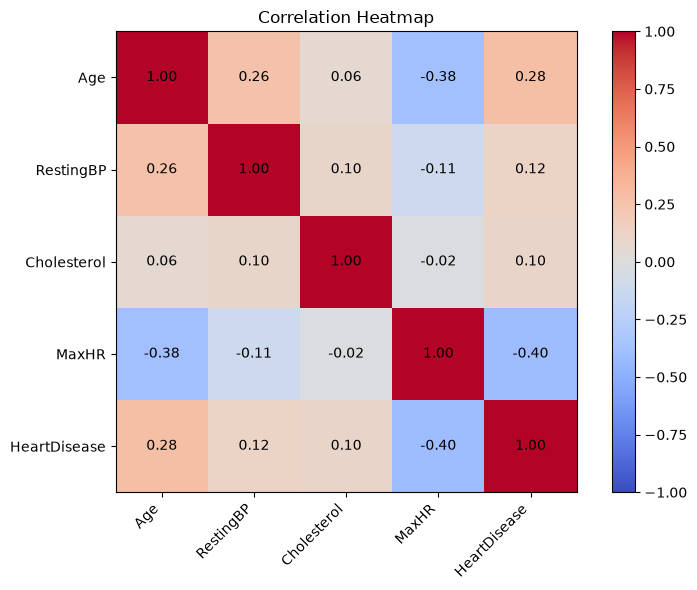

In [33]:
num_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "HeartDisease"]
corr = df[num_cols].corr()

plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(num_cols)), num_cols, rotation=45, ha="right")
plt.yticks(range(len(num_cols)), num_cols)

for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
## 5. Conclusions ##

**Dataset:** 917 patients (after cleaning), 55% with heart disease.

**Data quality findings:**
- 172 patients had Cholesterol = 0, which is physiologically impossible. 
  These were treated as missing values.
- 152 of these 172 (88%) had heart disease, so the missing values are 
  not random. Before cleaning, the data suggested patients had *lower* 
  cholesterol, which was misleading.
- One record with RestingBP = 0 was removed.

**Key findings:**
1. **Sex:** Heart disease rate was about 63% in men vs. 26% in women. 
   Only 193 women are in the dataset, so this should be interpreted carefully.
2. **Age:** Patients with heart disease were older on average 
   (55.9 vs 50.6 years), but the distributions overlap heavily.
3. **Chest pain type:** Asymptomatic patients (ASY) had the highest 
   rate (79%), suggesting silent disease is common in this sample.
4. **Cholesterol:** Slightly higher in patients with heart disease, 
   but the difference is small.
5. **Correlation:** MaxHR had the strongest relationship with heart 
   disease (-0.40), followed by Age (+0.28). Cholesterol and 
   resting blood pressure showed weak correlations.

**Limitations:**
- Hospital-referred patients, not a random population sample.
- Women are under-represented.
- Correlation does not imply causation.